In [2]:
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import pickle
from hypergraphx import Hypergraph



def hyperedge_homogeneity_list(H):
    edges = [list(e) for e in H.get_edges()]

    # pair_degree[(u, v)] = how many hyperedges contain that pair
    pair_degree = {}
    for edge in edges:
        for u, v in combinations(sorted(edge), 2):
            pair_degree[(u, v)] = pair_degree.get((u, v), 0) + 1

    homogeneity = []
    for edge in edges:
        if len(edge) <= 1:
            homogeneity.append(0.0)
            continue

        pair_values = []
        for u, v in combinations(sorted(edge), 2):
            pair_values.append(pair_degree[(u, v)])

        homogeneity.append(sum(pair_values) / len(pair_values))

    return homogeneity

In [ ]:
# All HyperLap datasets: hyperedge homogeneity + basic hypergraph stats
DATASET_DIR = Path("../www21-hyperlap-master/dataset").resolve()

homogeneity_by_dataset: dict = {}

for txt_path in sorted(DATASET_DIR.glob("*_graph.txt")):
    key = txt_path.stem.replace("_graph", "")
    print(key, flush=True)

    edge_list = []
    with open(txt_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tokens = line.replace(",", " ").split()
            edge_list.append([int(x) for x in tokens])

    H = Hypergraph(edge_list)
    hom_list = hyperedge_homogeneity_list(H)
    edge_sizes = [len(e) for e in H.get_edges()]

    homogeneity_by_dataset[key] = {
        "path": str(txt_path),
        "n_nodes": len(H.get_nodes()),
        "n_edges": len(H.get_edges()),
        "hyperedge_homogeneity": hom_list,
        "mean_homogeneity": np.mean(hom_list),
        "median_homogeneity": np.median(hom_list),
        "std_homogeneity": np.std(hom_list),
        "min_edge_size": min(edge_sizes),
        "max_edge_size": max(edge_sizes),
        "mean_edge_size": np.mean(edge_sizes),
    }


NDC-classes-full
NDC-substances-full
coauth-DBLP-full
coauth-geology-full
coauth-history-full
contact-high
contact-primary
email-Enron-full
email-Eu-full
tags-math
tags-ubuntu
threads-math
threads-ubuntu


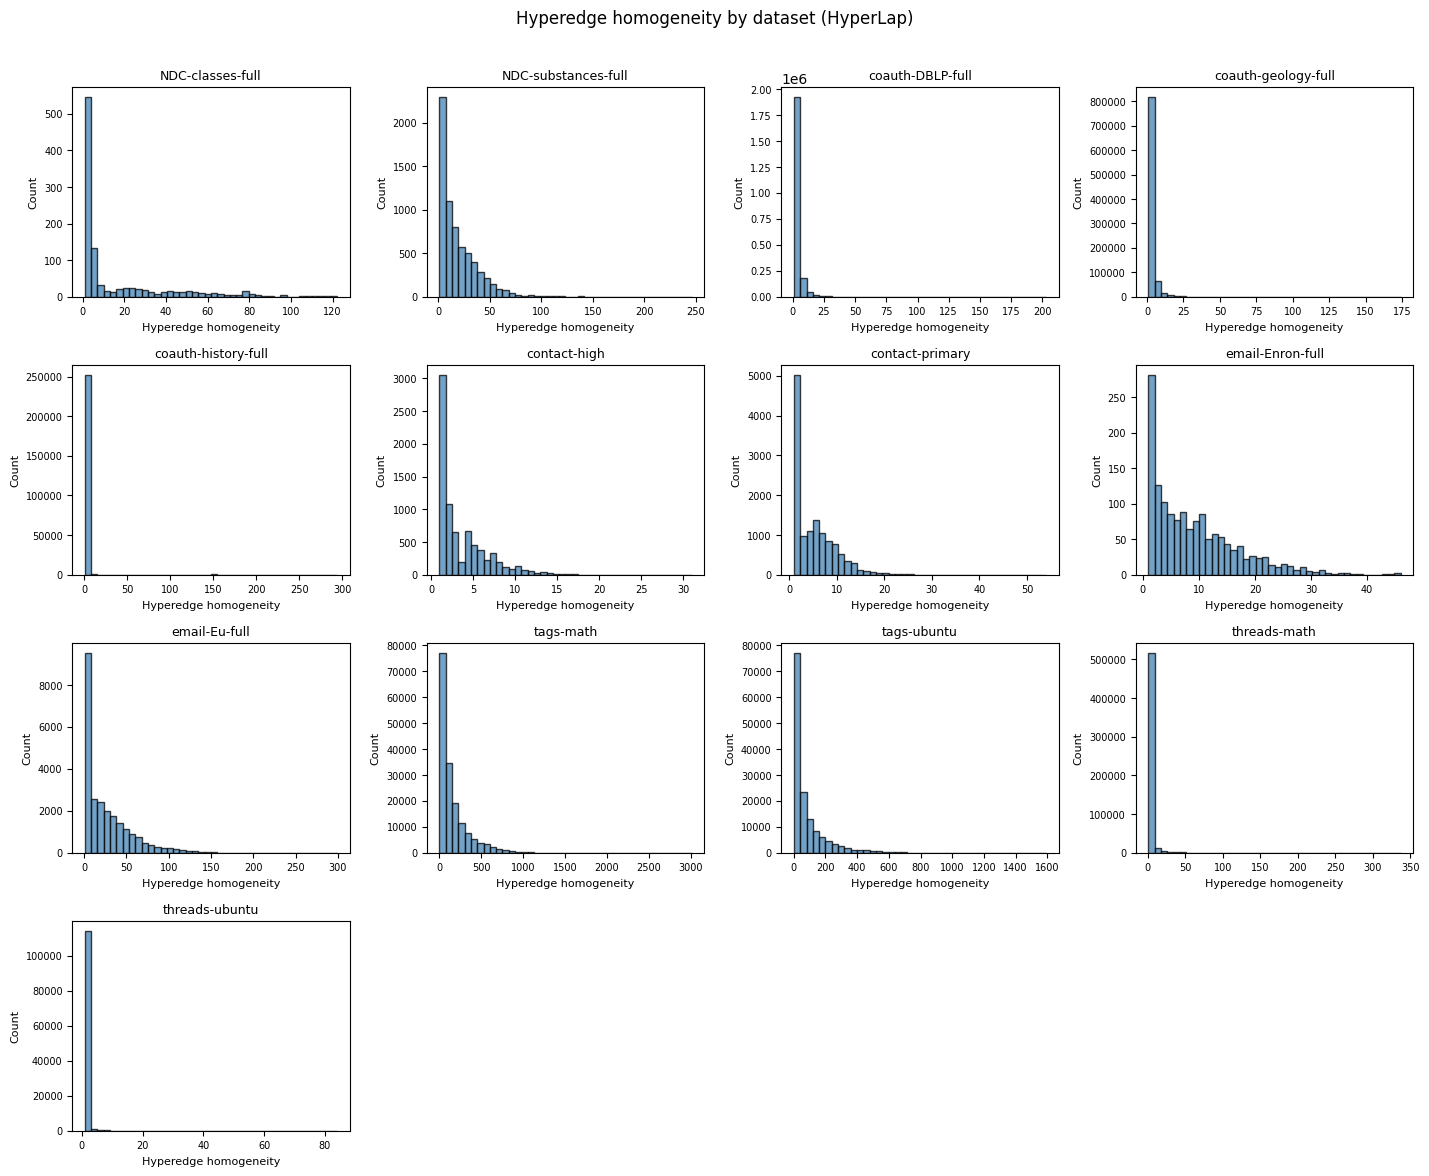

In [4]:
# Facet plot: one histogram per dataset
names = sorted(homogeneity_by_dataset.keys())
n = len(names)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.9 * nrows), squeeze=False)
axes_flat = axes.ravel()

for i, name in enumerate(names):
    ax = axes_flat[i]
    hom = homogeneity_by_dataset[name]["hyperedge_homogeneity"]
    ax.hist(hom, bins=40, edgecolor="black", alpha=0.75, color="steelblue")
    mu = float(homogeneity_by_dataset[name]["mean_homogeneity"])
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, label="mean")
    ax.legend(fontsize=6, loc="best")
    ax.set_title(
        f"{name}\n|V|={homogeneity_by_dataset[name]['n_nodes']:,}, |E|={homogeneity_by_dataset[name]['n_edges']:,}",
        fontsize=9,
    )
    ax.set_xlabel("Hyperedge homogeneity", fontsize=8)
    ax.set_ylabel("Count", fontsize=8)
    ax.tick_params(labelsize=7)

for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle("Hyperedge homogeneity by dataset (HyperLap)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()
